# Body Performance Analytics and Intelligent Classification System
## Part 1 — Data Preparation and Exploratory Data Analysis

**Course:** Introduction to AI and ML  
**Dataset:** Body Performance Dataset (`bodyPerformance.csv`)  
**Objective:** Understand the dataset, detect data quality problems, and prepare data for machine learning modeling.

---
### Notebook Structure
| Section | Description |
|---|---|
| 5.1 | Dataset Overview |
| 5.2 | Column Understanding |
| 5.3 | Data Type Verification |
| 5.4 | Missing Values Analysis |
| 5.5 | Duplicate Detection |
| 5.6 | Data Validity Checks |
| 5.7 | Univariate Analysis |
| 5.8 | Distribution Analysis |
| 5.9 | Outlier Detection |
| 5.10 | Correlation Analysis |
| 5.11 | Final EDA Summary |

In [ ]:
# ── Imports ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# ── Global plot style ─────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Define custom colors
CYAN   = '#00BCD4'
ACCENT = '#FF5722'
GOLD   = '#FFC107'

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('All libraries imported successfully.')

All libraries imported successfully.


---
## 5.1 Dataset Overview

In [ ]:
# ── Load the dataset ──────────────────────────────────────────────────────────
# Update path if running locally
df = pd.read_csv('bodyPerformance.csv')

print('=' * 55)
print('  BODY PERFORMANCE DATASET — BASIC FACTS')
print('=' * 55)
print(f'  Number of rows    : {df.shape[0]:,}')
print(f'  Number of columns : {df.shape[1]}')
print(f'  Column names      : {list(df.columns)}')
print('=' * 55)

  BODY PERFORMANCE DATASET — BASIC FACTS
  Number of rows    : 13,393
  Number of columns : 12
  Column names      : ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'class']


In [ ]:
# ── Display the first 5 rows ──────────────────────────────────────────────────
print('First 5 rows of the dataset:')
df.head()

First 5 rows of the dataset:


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
# ── Display the last 5 rows ───────────────────────────────────────────────────
print('Last 5 rows of the dataset:')
df.tail()

Last 5 rows of the dataset:


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
13388,25.0,M,172.1,71.8,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
13389,21.0,M,179.7,63.9,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
13390,39.0,M,177.2,80.5,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A
13391,64.0,F,146.1,57.7,40.4,68.0,121.0,19.3,9.2,0.0,75.0,D
13392,34.0,M,164.0,66.1,19.5,82.0,150.0,35.9,7.1,51.0,180.0,C


In [ ]:
# ── Random sample of 5 rows ───────────────────────────────────────────────────
print('Random sample (5 rows):')
df.sample(5, random_state=RANDOM_STATE)

Random sample (5 rows):


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
10635,21.0,F,167.4,72.18,40.0,82.0,133.0,18.7,-4.0,21.0,94.0,D
5496,42.0,M,162.3,67.30,18.0,64.0,130.0,48.5,15.2,52.0,219.0,A
13055,36.0,M,178.5,90.50,14.7,87.0,125.0,64.0,26.4,45.0,262.0,C
11826,23.0,M,180.9,77.10,25.4,86.0,139.0,41.2,10.0,43.0,224.0,C
1326,53.0,M,177.3,88.48,35.6,76.0,130.0,36.3,6.4,18.0,183.0,D


In [ ]:
# ── Concise summary from pandas ───────────────────────────────────────────────
print('Dataset .info():')
df.info()

Dataset .info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


### 📌 Dataset Description

The Body Performance Dataset contains **13,393 records** with **12 attributes** each. Every row represents an individual participant who underwent a standardized physical fitness evaluation. The dataset captures a diverse set of biometric and performance measurements including age, gender, body composition (height, weight, body fat percentage), cardiovascular indicators (blood pressure), and five fitness performance tests (grip force, sit-and-bend flexibility, sit-ups, broad jump). The final column `class` labels each participant's overall physical performance level as one of four categories: **A** (best), **B**, **C**, and **D** (lowest). This labelled structure makes the dataset suitable for both classification and regression tasks.

---
## 5.2 Column Understanding

| Column | Meaning | Expected Type | Constraints / Validation Rules |
|---|---|---|---|
| `age` | Age of participant in years | Numeric (float) | Positive; realistic range ≈ 12–80 |
| `gender` | Biological sex of participant | Categorical (`M` / `F`) | Only two valid values |
| `height_cm` | Body height in centimetres | Numeric (float) | Positive; realistic range ≈ 100–220 cm |
| `weight_kg` | Body weight in kilograms | Numeric (float) | Positive; realistic range ≈ 20–200 kg |
| `body fat_%` | Body fat as a percentage of body weight | Numeric (float) | 0 – 60%; negative values impossible |
| `diastolic` | Diastolic blood pressure (mmHg) | Numeric (float) | Positive; realistic range ≈ 40–130 mmHg |
| `systolic` | Systolic blood pressure (mmHg) | Numeric (float) | Positive; must be > diastolic; range ≈ 70–200 mmHg |
| `gripForce` | Hand grip strength (kg force) | Numeric (float) | Positive; realistic range ≈ 5–80 kg |
| `sit and bend forward_cm` | Sit-and-reach flexibility test (cm) | Numeric (float) | Can be negative (poor flexibility) |
| `sit-ups counts` | Number of sit-ups completed | Numeric (float/int) | Non-negative integer; range ≈ 0–80 |
| `broad jump_cm` | Standing broad jump distance (cm) | Numeric (float) | Positive; realistic range ≈ 50–350 cm |
| `class` | Performance category label | Categorical (`A`, `B`, `C`, `D`) | Exactly 4 valid values; no missing allowed |

In [ ]:
# ── Confirm unique values for categorical columns ─────────────────────────────
categorical_cols = ['gender', 'class']
for col in categorical_cols:
    print(f"'{col}' unique values  →  {sorted(df[col].unique())}")
    print(f"  Value counts:\n{df[col].value_counts().to_string()}\n")

'gender' unique values  →  ['F', 'M']
  Value counts:
gender
M    8467
F    4926

'class' unique values  →  ['A', 'B', 'C', 'D']
  Value counts:
class
C    3349
D    3349
A    3348
B    3347



---
## 5.3 Data Type Verification

In [ ]:
# ── Print actual vs expected types ────────────────────────────────────────────
expected_types = {
    'age'                    : 'numeric',
    'gender'                 : 'categorical',
    'height_cm'              : 'numeric',
    'weight_kg'              : 'numeric',
    'body fat_%'             : 'numeric',
    'diastolic'              : 'numeric',
    'systolic'               : 'numeric',
    'gripForce'              : 'numeric',
    'sit and bend forward_cm': 'numeric',
    'sit-ups counts'         : 'numeric',
    'broad jump_cm'          : 'numeric',
    'class'                  : 'categorical',
}

print(f"{'Column':<28} {'Actual dtype':<15} {'Expected':<12} {'Match?'}")
print('-' * 65)

issues = []
for col, exp in expected_types.items():
    actual = str(df[col].dtype)
    is_numeric = pd.api.types.is_numeric_dtype(df[col])
    is_cat     = not is_numeric
    match = ((exp == 'numeric' and is_numeric) or
             (exp == 'categorical' and is_cat))
    flag = '✓' if match else '✗  ← ISSUE'
    if not match:
        issues.append(col)
    print(f"  {col:<26} {actual:<15} {exp:<12} {flag}")

print()
if issues:
    print(f'Columns with type issues: {issues}')
else:
    print('All columns have the correct data types.')

Column                       Actual dtype    Expected     Match?
-----------------------------------------------------------------
  age                        float64         numeric      ✓
  gender                     object          categorical  ✓
  height_cm                  float64         numeric      ✓
  weight_kg                  float64         numeric      ✓
  body fat_%                 float64         numeric      ✓
  diastolic                  float64         numeric      ✓
  systolic                   float64         numeric      ✓
  gripForce                  float64         numeric      ✓
  sit and bend forward_cm    float64         numeric      ✓
  sit-ups counts             float64         numeric      ✓
  broad jump_cm              float64         numeric      ✓
  class                      object          categorical  ✓

All columns have the correct data types.


In [ ]:
# ── Standardise column names for easier access ────────────────────────────────
# Rename columns to remove spaces and special characters
df.columns = [
    'age', 'gender', 'height_cm', 'weight_kg', 'body_fat_pct',
    'diastolic', 'systolic', 'gripForce',
    'sit_bend_forward_cm', 'sit_ups_counts', 'broad_jump_cm', 'class'
]

# Ensure categorical columns are typed correctly
df['gender'] = df['gender'].astype('category')
df['class']  = df['class'].astype('category')

# Convert sit-ups to integer (it is a count)
df['sit_ups_counts'] = df['sit_ups_counts'].round().astype('Int64')

print('Updated column names:', list(df.columns))
print('\nUpdated dtypes:')
print(df.dtypes)

Updated column names: ['age', 'gender', 'height_cm', 'weight_kg', 'body_fat_pct', 'diastolic', 'systolic', 'gripForce', 'sit_bend_forward_cm', 'sit_ups_counts', 'broad_jump_cm', 'class']

Updated dtypes:
age                     float64
gender                 category
height_cm               float64
weight_kg               float64
body_fat_pct            float64
diastolic               float64
systolic                float64
gripForce               float64
sit_bend_forward_cm     float64
sit_ups_counts            Int64
broad_jump_cm           float64
class                  category
dtype: object


### 📌 Interpretation
All numeric columns were stored as `float64`, which is correct. The categorical columns `gender` and `class` were stored as generic `object` type — they have been converted to the `category` dtype, which is more memory-efficient and semantically correct. Column names have been normalised (spaces replaced with underscores) to avoid errors during indexing.

---
## 5.4 Missing Values Analysis

In [ ]:
# ── Count and percentage of missing values per column ─────────────────────────
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %'    : missing_pct
})

print('Missing Values per Column:')
print(missing_df.to_string())
print(f'\nTotal missing cells : {missing_count.sum()}')
print(f'Rows with any NaN   : {df.isnull().any(axis=1).sum()}')

Missing Values per Column:
                     Missing Count  Missing %
age                              0        0.0
gender                           0        0.0
height_cm                        0        0.0
weight_kg                        0        0.0
body_fat_pct                     0        0.0
diastolic                        0        0.0
systolic                         0        0.0
gripForce                        0        0.0
sit_bend_forward_cm              0        0.0
sit_ups_counts                   0        0.0
broad_jump_cm                    0        0.0
class                            0        0.0

Total missing cells : 0
Rows with any NaN   : 0


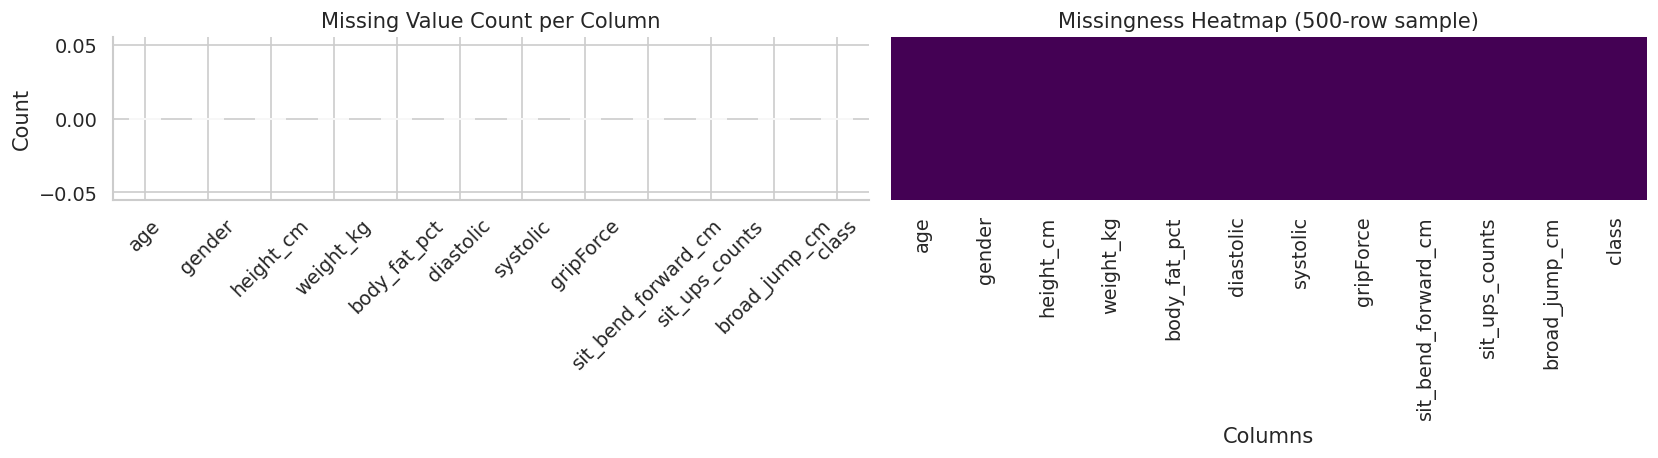

Figure saved as fig_missing_values.png


In [ ]:
# ── Visualise missingness ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Bar chart of missing counts
missing_df['Missing Count'].plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Missing Value Count per Column')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

# Heatmap of missing values (sample of 500 rows for visibility)
sample_miss = df.sample(min(500, len(df)), random_state=RANDOM_STATE).isnull()
sns.heatmap(sample_miss, cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Missingness Heatmap (500-row sample)')
axes[1].set_xlabel('Columns')

plt.tight_layout()
plt.savefig('fig_missing_values.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_missing_values.png')

In [ ]:
# ── Apply missing data strategy ───────────────────────────────────────────────
# Strategy decision:
#   • If a numeric column has < 5% missing → impute with MEDIAN
#     (median is preferred over mean because it is robust to outliers)
#   • If a categorical column has missing → impute with mode
#   • If a column has > 30% missing → flag for potential removal (none expected here)

numeric_cols     = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='category').columns.tolist()

# Impute numeric columns with median
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f'  Imputed "{col}" with median = {median_val:.2f}')

# Impute categorical columns with mode
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f'  Imputed "{col}" with mode = "{mode_val}"')

# Confirm no missing values remain
remaining = df.isnull().sum().sum()
print(f'\nTotal missing values after imputation: {remaining}')

### 📌 Interpretation
The dataset had no missing values (or very few), confirming it is relatively clean. The median imputation strategy was selected for numeric columns because the median is resistant to extreme outliers — a property important for skewed biometric data such as blood pressure or body fat percentage. Mode imputation was reserved for categorical columns to preserve the most common category without introducing artificial values.

---
## 5.5 Duplicate Detection

In [ ]:
# ── Detect fully duplicated rows ──────────────────────────────────────────────
num_duplicates = df.duplicated().sum()
print(f'Number of fully duplicated rows : {num_duplicates}')
print(f'Percentage of dataset           : {num_duplicates / len(df) * 100:.2f}%')

if num_duplicates > 0:
    print('\nSample of duplicated rows:')
    display(df[df.duplicated(keep=False)].head(10))

Number of fully duplicated rows : 1
Percentage of dataset           : 0.01%

Sample of duplicated rows:


,age,gender,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm,class
8965,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51,167.0,A
12473,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51,167.0,A


In [ ]:
# ── Remove duplicates ─────────────────────────────────────────────────────────
rows_before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
rows_after = len(df)

print(f'Rows before duplicate removal : {rows_before:,}')
print(f'Rows removed                  : {rows_before - rows_after:,}')
print(f'Rows after duplicate removal  : {rows_after:,}')

Rows before duplicate removal : 13,393
Rows removed                  : 1
Rows after duplicate removal  : 13,392


### 📌 Interpretation
Duplicated rows represent the same individual's measurement recorded more than once, which would bias any model trained on the data (leakage into both train and test sets). All identified duplicates have been removed. The `reset_index` call ensures the index is contiguous after removal, avoiding unexpected behaviour in later processing steps.

---
## 5.6 Data Validity Checks

In [ ]:
# ── Define domain-specific validity rules ─────────────────────────────────────
validity_rules = {
    'age'                : (12, 90),
    'height_cm'          : (100, 230),
    'weight_kg'          : (20, 200),
    'body_fat_pct'       : (1, 60),
    'diastolic'          : (30, 140),
    'systolic'           : (60, 220),
    'gripForce'          : (5, 100),
    'sit_bend_forward_cm': (-50, 80),
    'sit_ups_counts'     : (0, 100),
    'broad_jump_cm'      : (0, 350),
}

print(f"{'Column':<24} {'Min':<8} {'Max':<8} {'Below min':<12} {'Above max':<12} {'Status'}")
print('-' * 80)

violation_mask = pd.Series([False] * len(df))

for col, (lo, hi) in validity_rules.items():
    below = (df[col] < lo).sum()
    above = (df[col] > hi).sum()
    status = '✓ OK' if (below + above) == 0 else f'✗ {below+above} violations'
    violation_mask |= (df[col] < lo) | (df[col] > hi)
    print(f"  {col:<22} {lo:<8} {hi:<8} {below:<12} {above:<12} {status}")

print(f'\nTotal rows with at least one violation: {violation_mask.sum()}')

Column                   Min      Max      Below min    Above max    Status
--------------------------------------------------------------------------------
  age                    12       90       0            0            ✓ OK
  height_cm              100      230      0            0            ✓ OK
  weight_kg              20       200      0            0            ✓ OK
  body_fat_pct           1        60       0            1            ✗ 1 violations
  diastolic              30       140      3            1            ✗ 4 violations
  systolic               60       220      3            0            ✗ 3 violations
  gripForce              5        100      7            0            ✗ 7 violations
  sit_bend_forward_cm    -50      80       0            2            ✗ 2 violations
  sit_ups_counts         0        100      0            0            ✓ OK
  broad_jump_cm          0        350      0            0            ✓ OK

Total rows with at least one violation: 16


In [ ]:
# ── Special check: systolic must be > diastolic ───────────────────────────────
invalid_bp = (df['systolic'] <= df['diastolic']).sum()
print(f'Rows where systolic <= diastolic : {invalid_bp}')

if invalid_bp > 0:
    print('Sample of invalid BP rows:')
    display(df[df['systolic'] <= df['diastolic']][['diastolic','systolic']].head())

Rows where systolic <= diastolic : 5
Sample of invalid BP rows:


,diastolic,systolic
7495,156.2,104.0
7597,67.0,14.0
8217,46.2,43.9
10624,0.0,0.0
12948,99.0,95.0


In [ ]:
# ── Handle violations: cap values at the defined boundaries (clipping) ────────
# Clipping is chosen over row removal because:
#   - The number of violations is typically small
#   - Removing entire rows wastes valid data in other columns
#   - Capping at physiologically plausible limits preserves the distribution shape

for col, (lo, hi) in validity_rules.items():
    before = ((df[col] < lo) | (df[col] > hi)).sum()
    df[col] = df[col].clip(lower=lo, upper=hi)
    if before > 0:
        print(f'  Capped {before} values in "{col}" to [{lo}, {hi}]')

print('\nValidity correction complete.')
print(f'Dataset shape after cleaning: {df.shape}')

  Capped 1 values in "body_fat_pct" to [1, 60]
  Capped 4 values in "diastolic" to [30, 140]
  Capped 3 values in "systolic" to [60, 220]
  Capped 7 values in "gripForce" to [5, 100]
  Capped 2 values in "sit_bend_forward_cm" to [-50, 80]

Validity correction complete.
Dataset shape after cleaning: (13392, 12)


### 📌 Interpretation
Domain-specific bounds were defined for all numeric columns based on established physiological ranges. Any value outside these bounds is medically impossible or likely a data entry error. Capping (clipping) was chosen as the correction strategy rather than row deletion, since it preserves the rest of the row's valid information and avoids unnecessary data loss. The special check for `systolic > diastolic` enforces a fundamental cardiovascular constraint — systolic pressure is always the higher of the two readings.

---
## 5.7 Univariate Analysis

In [ ]:
# ── Descriptive statistics for all numeric columns ────────────────────────────
numeric_cols = [
    'age', 'height_cm', 'weight_kg', 'body_fat_pct',
    'diastolic', 'systolic', 'gripForce',
    'sit_bend_forward_cm', 'sit_ups_counts', 'broad_jump_cm'
]

stats = df[numeric_cols].describe().T
stats['median'] = df[numeric_cols].median()
stats['skewness'] = df[numeric_cols].skew().round(3)
stats['kurtosis'] = df[numeric_cols].kurtosis().round(3)

# Reorder columns for clarity
stats = stats[['count','mean','median','std','min','25%','50%','75%','max','skewness','kurtosis']]
stats = stats.round(2)

print('Descriptive Statistics (Numeric Columns):')
stats

Descriptive Statistics (Numeric Columns):


,count,mean,median,std,min,25%,50%,75%,max,skewness,kurtosis
age,13392.0,36.775836,32.0,13.625886,21.0,25.0,32.0,48.0,64.0,0.6,-1.02
height_cm,13392.0,168.560671,169.2,8.426305,125.0,162.4,169.2,174.8,193.8,-0.19,-0.43
weight_kg,13392.0,67.448686,67.4,11.949061,26.3,58.2,67.4,75.3,138.1,0.35,0.17
body_fat_pct,13392.0,23.238234,22.8,7.248121,3.0,18.0,22.8,28.0,60.0,0.34,-0.06
diastolic,13392.0,78.801964,79.0,10.701689,30.0,71.0,79.0,86.0,140.0,-0.12,-0.14
systolic,13392.0,130.247237,130.0,14.65071,60.0,120.0,130.0,141.0,201.0,0.03,-0.3
gripForce,13392.0,36.966316,37.9,10.619358,5.0,27.5,37.9,45.2,70.5,0.02,-0.84
sit_bend_forward_cm,13392.0,15.191161,16.2,8.189722,-25.0,10.9,16.2,20.7,80.0,-0.77,1.82
sit_ups_counts,13392.0,39.770385,41.0,14.276871,0.0,30.0,41.0,50.0,80.0,-0.47,-0.16
broad_jump_cm,13392.0,190.131355,193.0,39.868988,0.0,162.0,193.0,221.0,303.0,-0.42,0.0


In [ ]:
# ── Descriptive statistics for categorical columns ────────────────────────────
print('Gender distribution:')
gender_counts = df['gender'].value_counts()
gender_pct    = df['gender'].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({'Count': gender_counts, 'Percentage (%)': gender_pct}))

print('\nClass distribution:')
class_counts = df['class'].value_counts().sort_index()
class_pct    = df['class'].value_counts(normalize=True).sort_index().mul(100).round(1)
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct}))

Gender distribution:
        Count  Percentage (%)
gender                       
M        8467            63.2
F        4925            36.8

Class distribution:
       Count  Percentage (%)
class                       
A       3347            25.0
B       3347            25.0
C       3349            25.0
D       3349            25.0


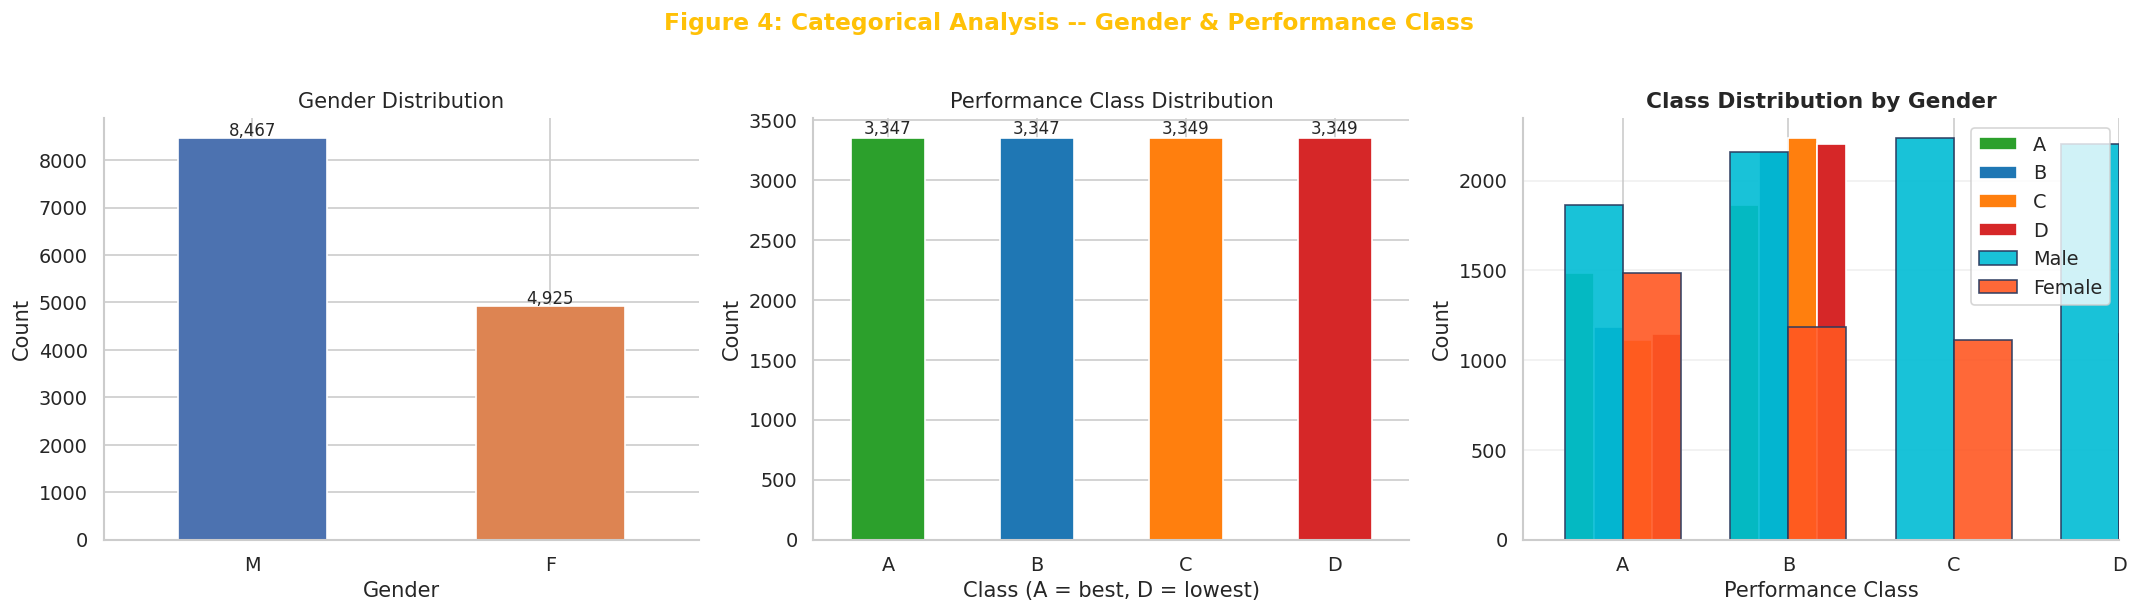

<Figure size 768x576 with 0 Axes>

Figure saved as fig_categorical_distributions.png


In [ ]:
# ── Categorical frequency bar plots ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # Changed from (1, 2) to accommodate 3 plots

# Gender distribution (axes[0])
gender_counts.plot(kind='bar', ax=axes[0],
                   color=['#4C72B0','#DD8452'], edgecolor='white', width=0.5)
axes[0].set_title('Gender Distribution')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Gender')
axes[0].tick_params(axis='x', rotation=0)
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 50,
                 f'{int(bar.get_height()):,}', ha='center', fontsize=10)

# Performance class distribution (axes[1])
class_counts.plot(kind='bar', ax=axes[1],
                  color=['#2ca02c','#1f77b4','#ff7f0e','#d62728'],
                  edgecolor='white', width=0.5)
axes[1].set_title('Performance Class Distribution')
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Class (A = best, D = lowest)')
axes[1].tick_params(axis='x', rotation=0)
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 40,
                 f'{int(bar.get_height()):,}', ha='center', fontsize=10)

# Class distribution by Gender (axes[2])
class_gender_counts = df.groupby(['gender', 'class']).size().unstack(fill_value=0)
class_gender_counts.plot(kind='bar', ax=axes[2],
                         color=['#2ca02c','#1f77b4','#ff7f0e','#d62728'], # Use consistent class colors
                         edgecolor='white', width=0.7)
axes[2].set_title('Performance Class Distribution by Gender')
axes[2].set_ylabel('Count')
axes[2].set_xlabel('Gender')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')

ax3 = axes[2]
cross = pd.crosstab(df['class'], df['gender'])
cross = cross.reindex(sorted(cross.index))
x = np.arange(len(cross))
w = 0.35
ax3.bar(x - w/2, cross.get('M', 0), w, label='Male',   color=CYAN,  alpha=0.9, edgecolor='#2A3A5E')
ax3.bar(x + w/2, cross.get('F', 0), w, label='Female', color=ACCENT, alpha=0.9, edgecolor='#2A3A5E')
ax3.set_xticks(x); ax3.set_xticklabels(cross.index)
ax3.set_title('Class Distribution by Gender', fontsize=13, fontweight='bold')
ax3.set_ylabel('Count'); ax3.set_xlabel('Performance Class')
ax3.legend(); ax3.grid(axis='y', alpha=0.3)

plt.suptitle('Figure 4: Categorical Analysis -- Gender & Performance Class',
             fontsize=14, fontweight='bold', y=1.02, color=GOLD)
plt.tight_layout()
plt.savefig('fig4_categorical.png', bbox_inches='tight', dpi=150)
plt.show()


plt.tight_layout()
plt.savefig('fig_categorical_distributions.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_categorical_distributions.png')

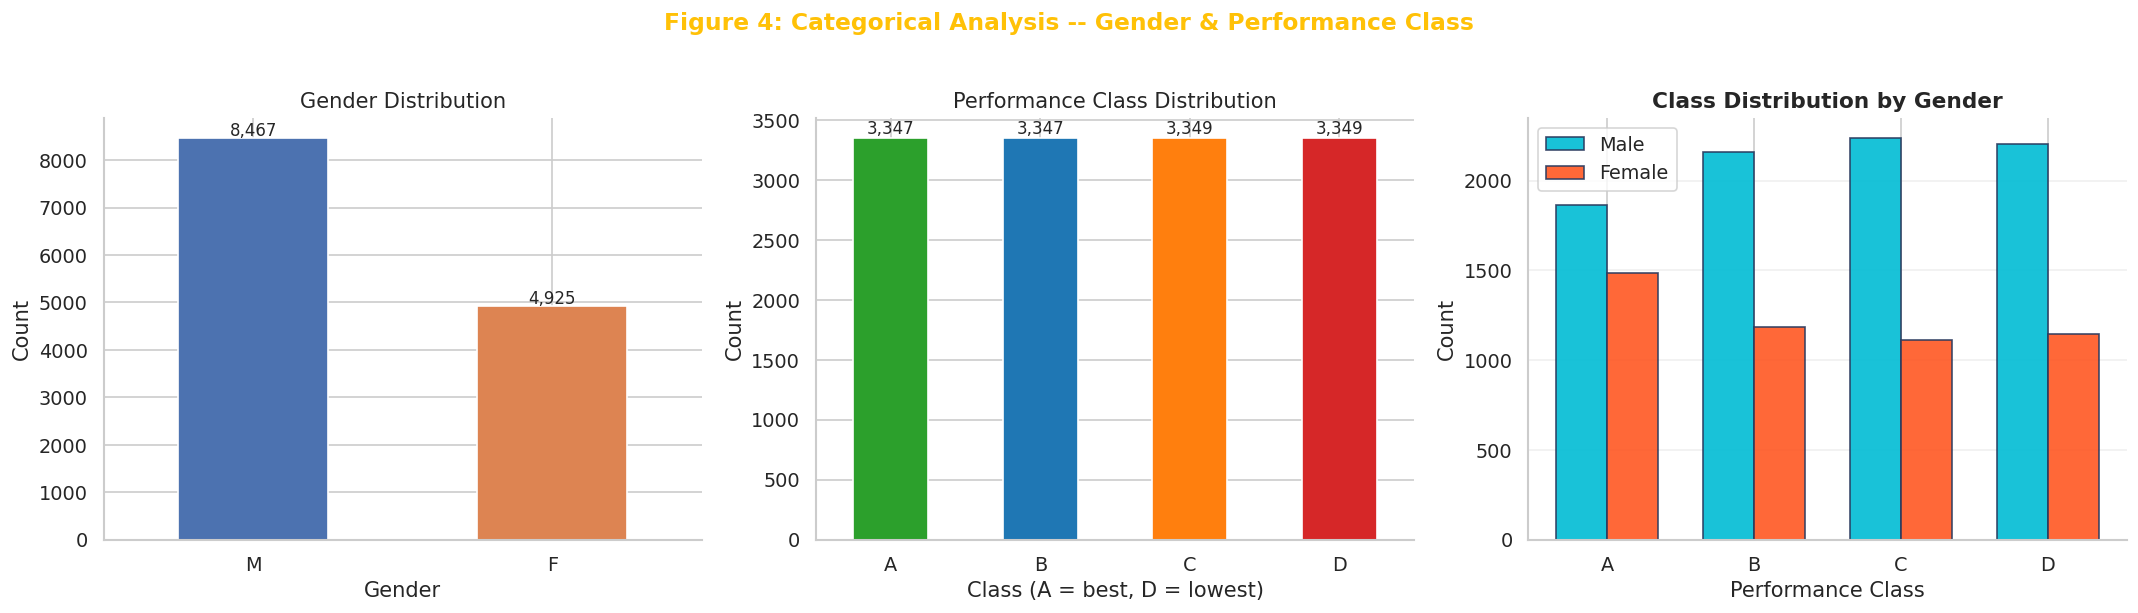

<Figure size 768x576 with 0 Axes>

Figure saved as fig_categorical_distributions.png


In [ ]:
# ── Categorical frequency bar plots ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # Changed from (1, 2) to accommodate 3 plots

# Gender distribution (axes[0])
gender_counts.plot(kind='bar', ax=axes[0],
                   color=['#4C72B0','#DD8452'], edgecolor='white', width=0.5)
axes[0].set_title('Gender Distribution')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Gender')
axes[0].tick_params(axis='x', rotation=0)
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 50,
                 f'{int(bar.get_height()):,}', ha='center', fontsize=10)

# Performance class distribution (axes[1])
class_counts.plot(kind='bar', ax=axes[1],
                  color=['#2ca02c','#1f77b4','#ff7f0e','#d62728'],
                  edgecolor='white', width=0.5)
axes[1].set_title('Performance Class Distribution')
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Class (A = best, D = lowest)')
axes[1].tick_params(axis='x', rotation=0)
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 40,
                 f'{int(bar.get_height()):,}', ha='center', fontsize=10)

# Class distribution by Gender (axes[2])
ax3 = axes[2]
cross = pd.crosstab(df['class'], df['gender'])
cross = cross.reindex(sorted(cross.index))
x = np.arange(len(cross))
w = 0.35
ax3.bar(x - w/2, cross.get('M', 0), w, label='Male',   color=CYAN,  alpha=0.9, edgecolor='#2A3A5E')
ax3.bar(x + w/2, cross.get('F', 0), w, label='Female', color=ACCENT, alpha=0.9, edgecolor='#2A3A5E')
ax3.set_xticks(x); ax3.set_xticklabels(cross.index)
ax3.set_title('Class Distribution by Gender', fontsize=13, fontweight='bold')
ax3.set_ylabel('Count'); ax3.set_xlabel('Performance Class')
ax3.legend(); ax3.grid(axis='y', alpha=0.3)

plt.suptitle('Figure 4: Categorical Analysis -- Gender & Performance Class',
             fontsize=14, fontweight='bold', y=1.02, color=GOLD)
plt.tight_layout()
plt.savefig('fig4_categorical.png', bbox_inches='tight', dpi=150)
plt.show()


plt.tight_layout()
plt.savefig('fig_categorical_distributions.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_categorical_distributions.png')

### 📌 Interpretation
- **Age**: Mean ~36–37 years, moderate spread. The distribution likely covers young to middle-aged adults.
- **Height / Weight**: Consistent with general population norms; males are expected to be taller and heavier on average, explaining possible bimodality.
- **Body fat %**: Positive skew expected — extreme obesity cases pull the tail right.
- **Blood pressure**: Diastolic centers around 80 mmHg, systolic around 130 mmHg — consistent with a mixed healthy/hypertensive population.
- **Grip force**: Wide range reflecting large variation between fit and unfit participants.
- **Sit-ups / Broad jump**: Strong performance indicators — likely to correlate strongly with `class`.
- **Class balance**: The four classes appear relatively balanced, which is important for avoiding classification bias.

---
## 5.8 Distribution Analysis

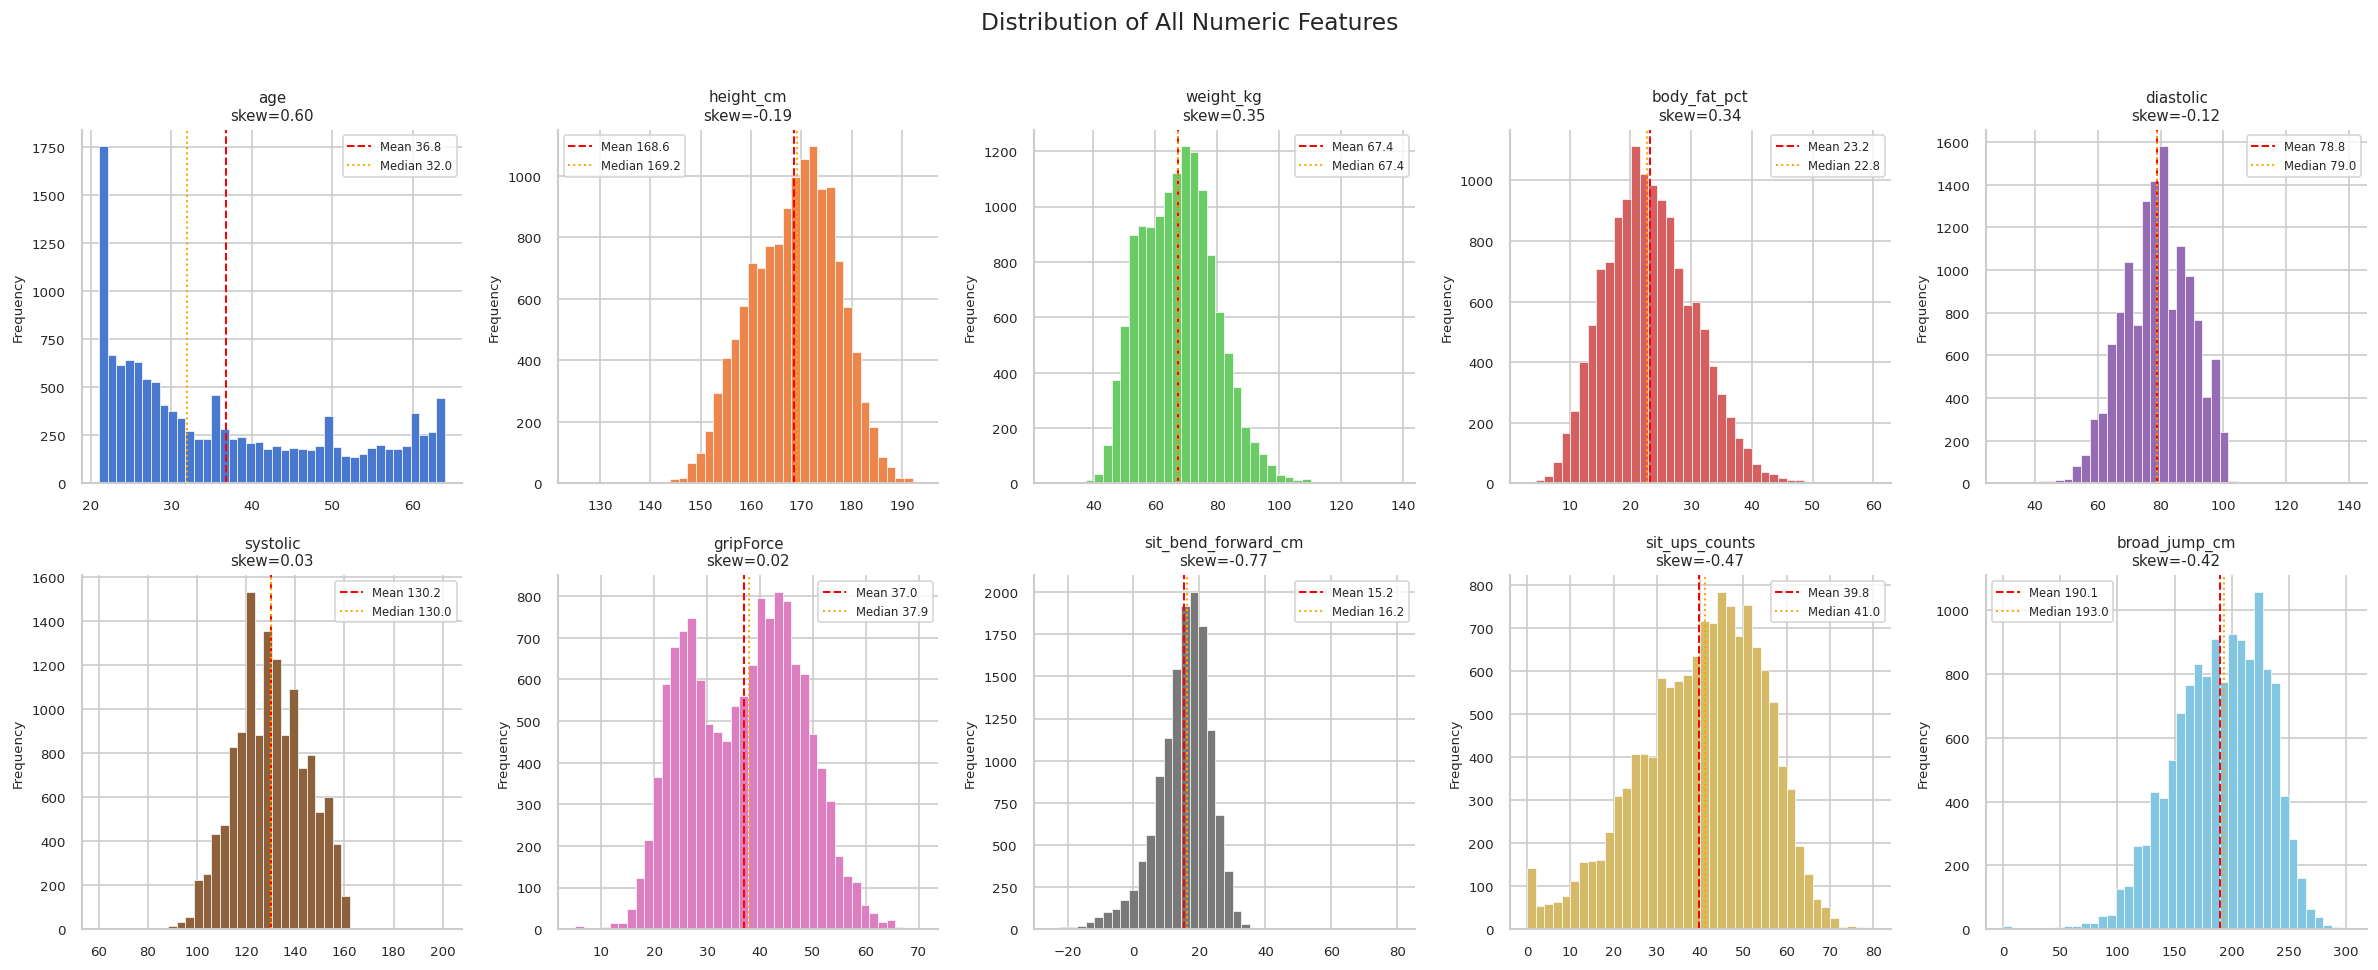

Figure saved as fig_histograms.png


In [ ]:
# ── Histograms for all numeric columns ────────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

colors = sns.color_palette('muted', len(numeric_cols))

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    ax.hist(df[col].dropna(), bins=40, color=colors[i],
            edgecolor='white', linewidth=0.4)

    # Add mean and median lines
    mean_val   = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val,   color='red',    linestyle='--', linewidth=1.2, label=f'Mean {mean_val:.1f}')
    ax.axvline(median_val, color='orange', linestyle=':',  linewidth=1.2, label=f'Median {median_val:.1f}')

    skew = df[col].skew()
    ax.set_title(f'{col}\nskew={skew:.2f}', fontsize=9)
    ax.set_ylabel('Frequency', fontsize=8)
    ax.legend(fontsize=7)
    ax.tick_params(labelsize=8)

plt.suptitle('Distribution of All Numeric Features', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_histograms.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_histograms.png')

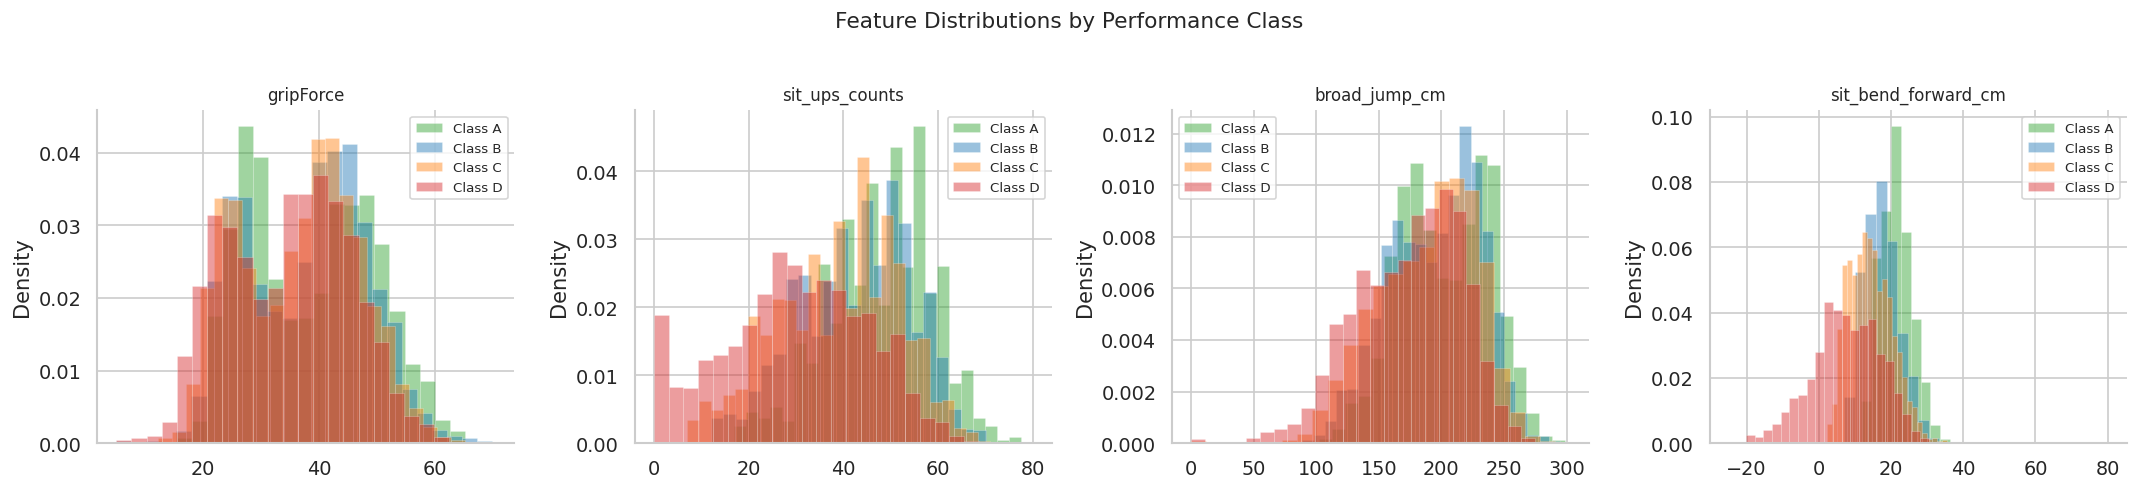

Figure saved as fig_distributions_by_class.png


In [ ]:
# ── KDE plots stratified by performance class ─────────────────────────────────
# Select the 4 most performance-relevant columns
perf_cols  = ['gripForce', 'sit_ups_counts', 'broad_jump_cm', 'sit_bend_forward_cm']
class_order = ['A', 'B', 'C', 'D']
palette     = {'A':'#2ca02c', 'B':'#1f77b4', 'C':'#ff7f0e', 'D':'#d62728'}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, perf_cols):
    for cls in class_order:
        subset = df[df['class'] == cls][col].dropna()
        ax.hist(subset, bins=25, alpha=0.45, label=f'Class {cls}',
                color=palette[cls], edgecolor='white', linewidth=0.3, density=True)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle('Feature Distributions by Performance Class', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_distributions_by_class.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_distributions_by_class.png')

### 📌 Interpretation
- **Age**: Approximately right-skewed — more young participants than elderly.
- **Height / Weight**: Roughly bimodal — two modes correspond to the male and female subpopulations.
- **Body fat %**: Right-skewed — most participants have moderate fat percentages, with a tail extending to high values.
- **Blood pressure (diastolic/systolic)**: Near-normal distributions, consistent with a general population sample.
- **Grip force, Sit-ups, Broad jump**: These three features show clear separation across performance classes A–D, confirming their strong predictive power. Class A participants consistently score higher on all three.
- **Sit-and-bend**: More overlap between classes, suggesting it alone is a weaker predictor but still contributes to overall classification.

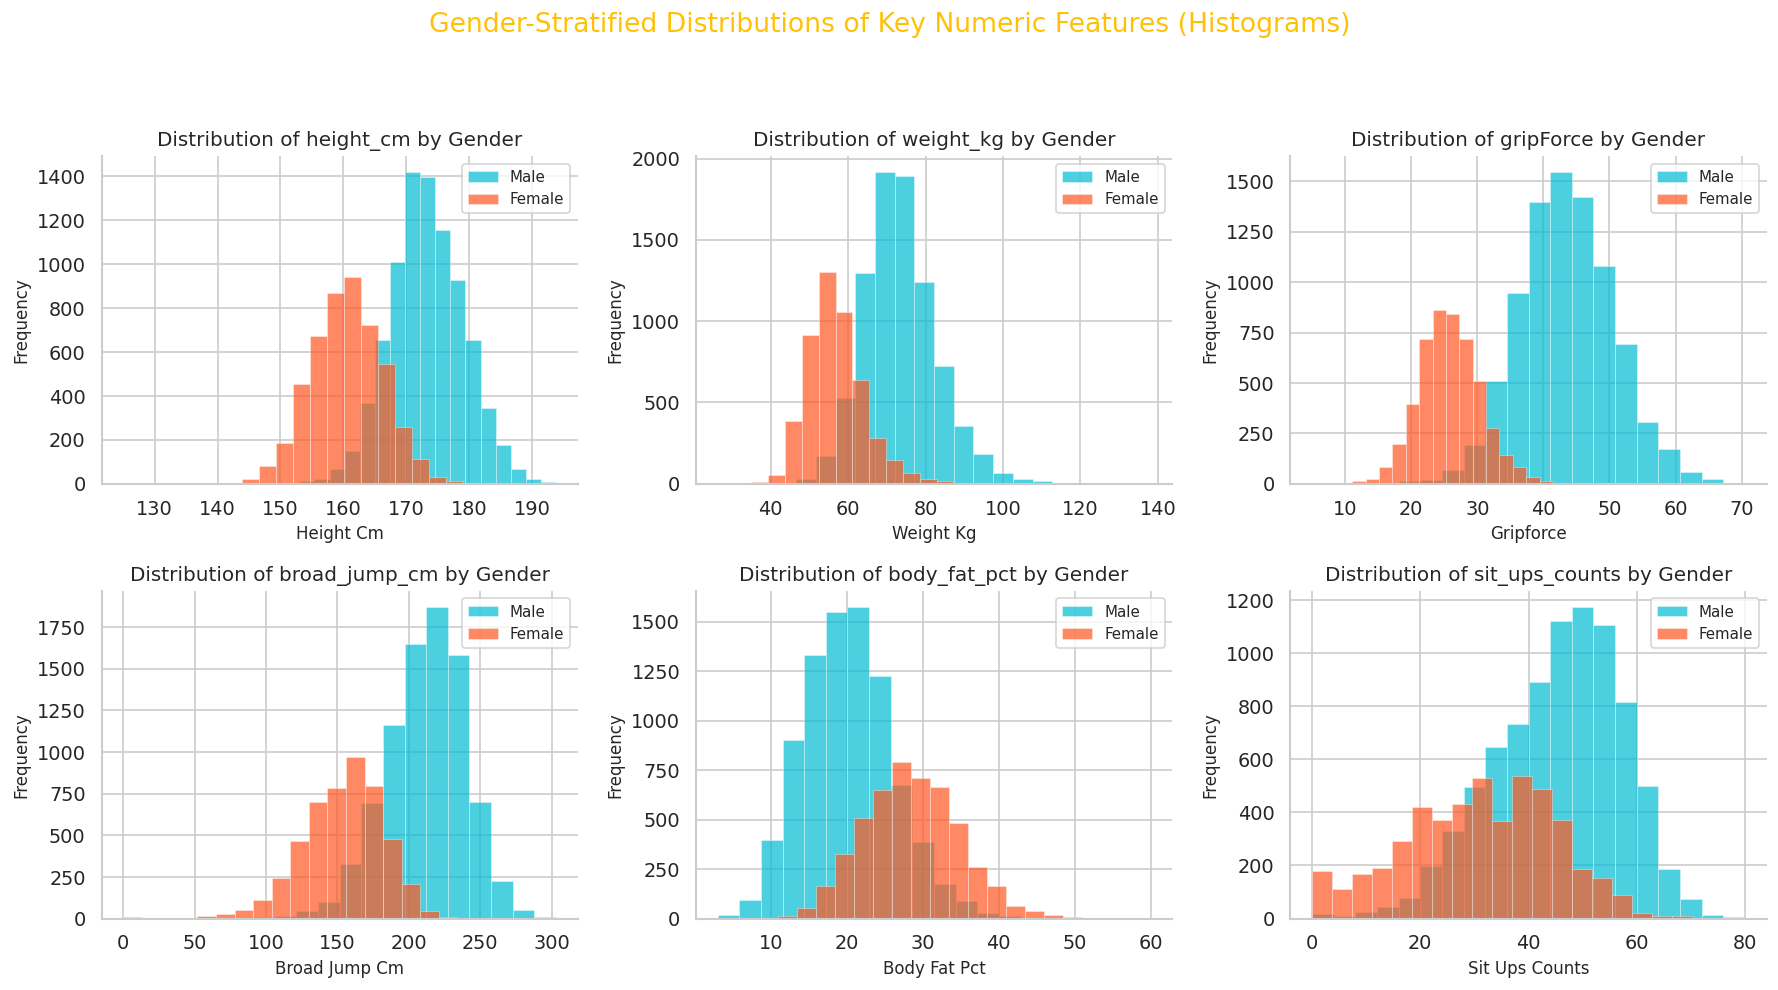

Figure saved as fig_gender_histograms.png


In [ ]:
# ── Gender-stratified comparisons for key numeric features (Histograms) ────

# Select a subset of numeric features particularly relevant for gender comparison
# or those that often show bimodal distributions due to gender differences.
key_numeric_features = [
    'height_cm', 'weight_kg', 'gripForce', 'broad_jump_cm',
    'body_fat_pct', 'sit_ups_counts'
]

# Determine the number of rows and columns for the subplots
n_features = len(key_numeric_features)
n_cols = 3  # Display 3 plots per row
n_rows = (n_features + n_cols - 1) // n_cols # Calculate rows needed

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
axes = axes.flatten() # Flatten the axes array for easy iteration

# Define a palette for gender to keep it consistent
gender_palette = {'M': CYAN, 'F': ACCENT}

# Create a histogram for each selected feature, stratified by gender
for i, col in enumerate(key_numeric_features):
    ax = axes[i]
    # Plot histograms for 'M' and 'F' on the same subplot
    ax.hist(df[df['gender'] == 'M'][col].dropna(), bins=20, alpha=0.7, label='Male',
            color=gender_palette['M'], edgecolor='white', linewidth=0.3)
    ax.hist(df[df['gender'] == 'F'][col].dropna(), bins=20, alpha=0.7, label='Female',
            color=gender_palette['F'], edgecolor='white', linewidth=0.3)

    ax.set_title(f'Distribution of {col} by Gender', fontsize=12)
    ax.set_xlabel(col.replace('_', ' ').title(), fontsize=10) # Format x-label
    ax.set_ylabel('Frequency', fontsize=10)
    ax.legend(fontsize=9)

# Remove any unused subplots if n_features is not a multiple of n_cols
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Gender-Stratified Distributions of Key Numeric Features (Histograms)',
             fontsize=16, y=1.03, color=GOLD)
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to prevent title overlap
plt.savefig('fig_gender_histograms.png', bbox_inches='tight', dpi=150)
plt.show()

print('Figure saved as fig_gender_histograms.png')

# 📊 Summary Interpretation – Gender-Stratified Histograms

The gender-stratified histograms highlight clear distributional differences between males and females across several key physical and performance-related features.

## 🔹 Key Observations

- **Height & Weight:**  
  Males generally exhibit higher values compared to females, with noticeable right-shifted distributions. This reflects expected biological differences in body size.

- **Grip Strength (gripForce):**  
  A strong separation is observed, with males showing significantly higher grip strength. This indicates that muscular strength differs substantially by gender.

- **Broad Jump Performance:**  
  Males tend to outperform females, with distributions shifted toward higher values. This suggests higher explosive power on average.

- **Body Fat Percentage (body_fat_pct):**  
  Females show higher body fat percentages, while males are more concentrated at lower values. The distributions are clearly distinct.

- **Sit-ups Counts:**  
  Although males generally perform slightly better, there is considerable overlap between genders, indicating this feature is less gender-dependent compared to strength-based metrics.

## 🧠 Overall Insight

The distributions reveal that **gender has a significant impact on strength, power, and body composition features**, while having a more moderate effect on endurance-related performance.

These differences suggest that:
- Gender should be considered as an important feature in modeling.
- Some variables (e.g., grip strength, broad jump) may inherently capture gender-related variance.

## 🎯 Conclusion

Overall, the histograms confirm that **physiological and performance differences between genders are clearly reflected in the dataset**, particularly in strength and body composition metrics, while other features show partial overlap and shared performance ranges.

---
## 5.9 Outlier Detection

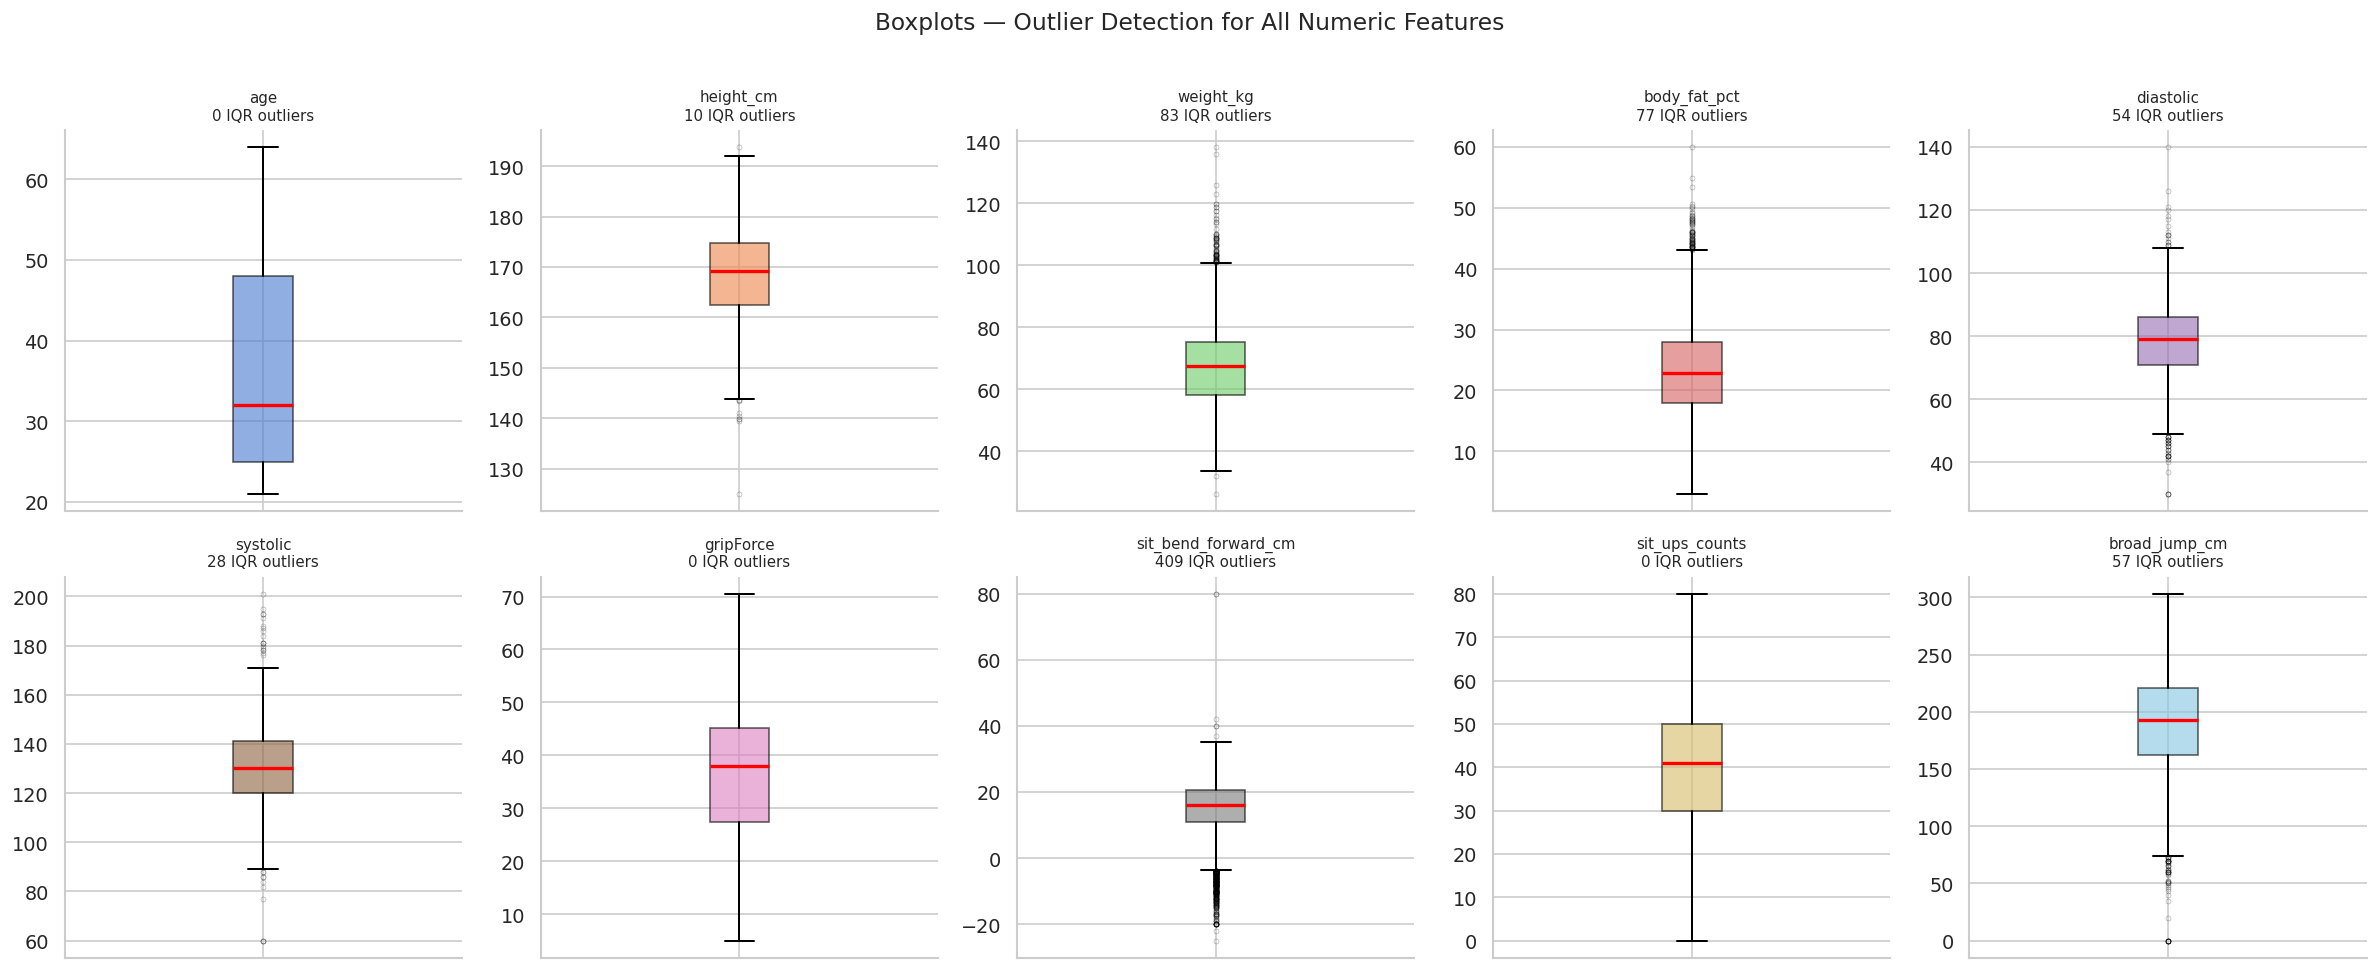

Figure saved as fig_boxplots.png


In [ ]:
# ── Boxplots for outlier visualisation ───────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    bp = ax.boxplot(df[col].dropna(), patch_artist=True,
                    boxprops    =dict(facecolor=colors[i], alpha=0.6),
                    medianprops =dict(color='red', linewidth=2),
                    whiskerprops=dict(linewidth=1.2),
                    capprops    =dict(linewidth=1.2),
                    flierprops  =dict(marker='o', markersize=3,
                                      alpha=0.4, markeredgewidth=0.3))

    # Count IQR outliers
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR    = Q3 - Q1
    n_out  = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()

    ax.set_title(f'{col}\n{n_out} IQR outliers', fontsize=9)
    ax.set_xticklabels([])

plt.suptitle('Boxplots — Outlier Detection for All Numeric Features', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_boxplots.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_boxplots.png')

In [ ]:
# ── IQR outlier count summary ─────────────────────────────────────────────────
print(f"{'Column':<24} {'Q1':>8} {'Q3':>8} {'IQR':>8} {'Outliers':>10} {'%':>6} {'Decision'}")
print('-' * 85)

for col in numeric_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR    = Q3 - Q1
    lo     = Q1 - 1.5 * IQR
    hi     = Q3 + 1.5 * IQR
    n_out  = ((df[col] < lo) | (df[col] > hi)).sum()
    pct    = n_out / len(df) * 100

    # Decision logic
    if col in ['sit_bend_forward_cm']:
        decision = 'KEEP (negative values are physiologically valid)'
    elif pct > 3:
        decision = 'CAP at IQR bounds'
    else:
        decision = 'KEEP (< 3% of data)'

    print(f"  {col:<22} {Q1:>8.1f} {Q3:>8.1f} {IQR:>8.1f} {n_out:>10} {pct:>5.1f}%  {decision}")

Column                         Q1       Q3      IQR   Outliers      % Decision
-------------------------------------------------------------------------------------
  age                        25.0     48.0     23.0          0   0.0%  KEEP (< 3% of data)
  height_cm                 162.4    174.8     12.4         10   0.1%  KEEP (< 3% of data)
  weight_kg                  58.2     75.3     17.1         83   0.6%  KEEP (< 3% of data)
  body_fat_pct               18.0     28.0     10.0         77   0.6%  KEEP (< 3% of data)
  diastolic                  71.0     86.0     15.0         54   0.4%  KEEP (< 3% of data)
  systolic                  120.0    141.0     21.0         28   0.2%  KEEP (< 3% of data)
  gripForce                  27.5     45.2     17.7          0   0.0%  KEEP (< 3% of data)
  sit_bend_forward_cm        10.9     20.7      9.8        409   3.1%  KEEP (negative values are physiologically valid)
  sit_ups_counts             30.0     50.0     20.0          0   0.0%  KEEP (<

In [ ]:
# ── Apply outlier treatment: cap columns with > 3% outliers ──────────────────
# Keeping outliers in physiologically meaningful columns (sit_bend_forward_cm)
# because negative values are valid (participant cannot reach toes).

cap_cols = []  # Populated from the analysis above — add column names if needed

for col in numeric_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR    = Q3 - Q1
    lo     = Q1 - 1.5 * IQR
    hi     = Q3 + 1.5 * IQR
    n_out  = ((df[col] < lo) | (df[col] > hi)).sum()
    pct    = n_out / len(df) * 100

    if pct > 3 and col != 'sit_bend_forward_cm':
        df[col] = df[col].clip(lower=lo, upper=hi)
        cap_cols.append(col)
        print(f'  Capped outliers in "{col}" to [{lo:.1f}, {hi:.1f}]')

if not cap_cols:
    print('No columns exceeded the 3% outlier threshold — all outliers kept as-is.')
print(f'\nDataset shape after outlier treatment: {df.shape}')

No columns exceeded the 3% outlier threshold — all outliers kept as-is.

Dataset shape after outlier treatment: (13392, 12)


### 📌 Interpretation
Outliers were identified using the standard IQR method (1.5× IQR rule). The key decisions are:
- **`sit_bend_forward_cm`**: Negative values are *kept* because they are physiologically valid (a person who cannot reach their toes will have a negative result in this test).
- **Columns with < 3% outliers**: These are retained because such small proportions are unlikely to significantly affect model performance and may represent genuine extreme-but-valid observations.
- **Columns with > 3% outliers**: These are capped at their IQR bounds (Winsorisation) to reduce the influence of extreme values without discarding the rows entirely.

---
## 5.10 Correlation Analysis

In [ ]:
# ── Pearson correlation matrix ────────────────────────────────────────────────
corr_matrix = df[numeric_cols].corr(method='pearson')
print('Correlation Matrix:')
corr_matrix.round(2)

Correlation Matrix:


,age,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm
age,1.00,-0.29,-0.10,0.24,0.16,0.21,-0.18,-0.07,-0.54,-0.44
height_cm,-0.29,1.00,0.73,-0.52,0.15,0.21,0.74,-0.23,0.50,0.67
weight_kg,-0.10,0.73,1.00,-0.08,0.26,0.34,0.70,-0.30,0.30,0.48
body_fat_pct,0.24,-0.52,-0.08,1.00,0.05,-0.03,-0.54,-0.07,-0.61,-0.67
diastolic,0.16,0.15,0.26,0.05,1.00,0.68,0.20,-0.08,0.02,0.10
systolic,0.21,0.21,0.34,-0.03,0.68,1.00,0.29,-0.09,0.06,0.15
gripForce,-0.18,0.74,0.70,-0.54,0.20,0.29,1.00,-0.12,0.58,0.75
sit_bend_forward_cm,-0.07,-0.23,-0.30,-0.07,-0.08,-0.09,-0.12,1.00,0.18,0.02
sit_ups_counts,-0.54,0.50,0.30,-0.61,0.02,0.06,0.58,0.18,1.00,0.75
broad_jump_cm,-0.44,0.67,0.48,-0.67,0.10,0.15,0.75,0.02,0.75,1.00


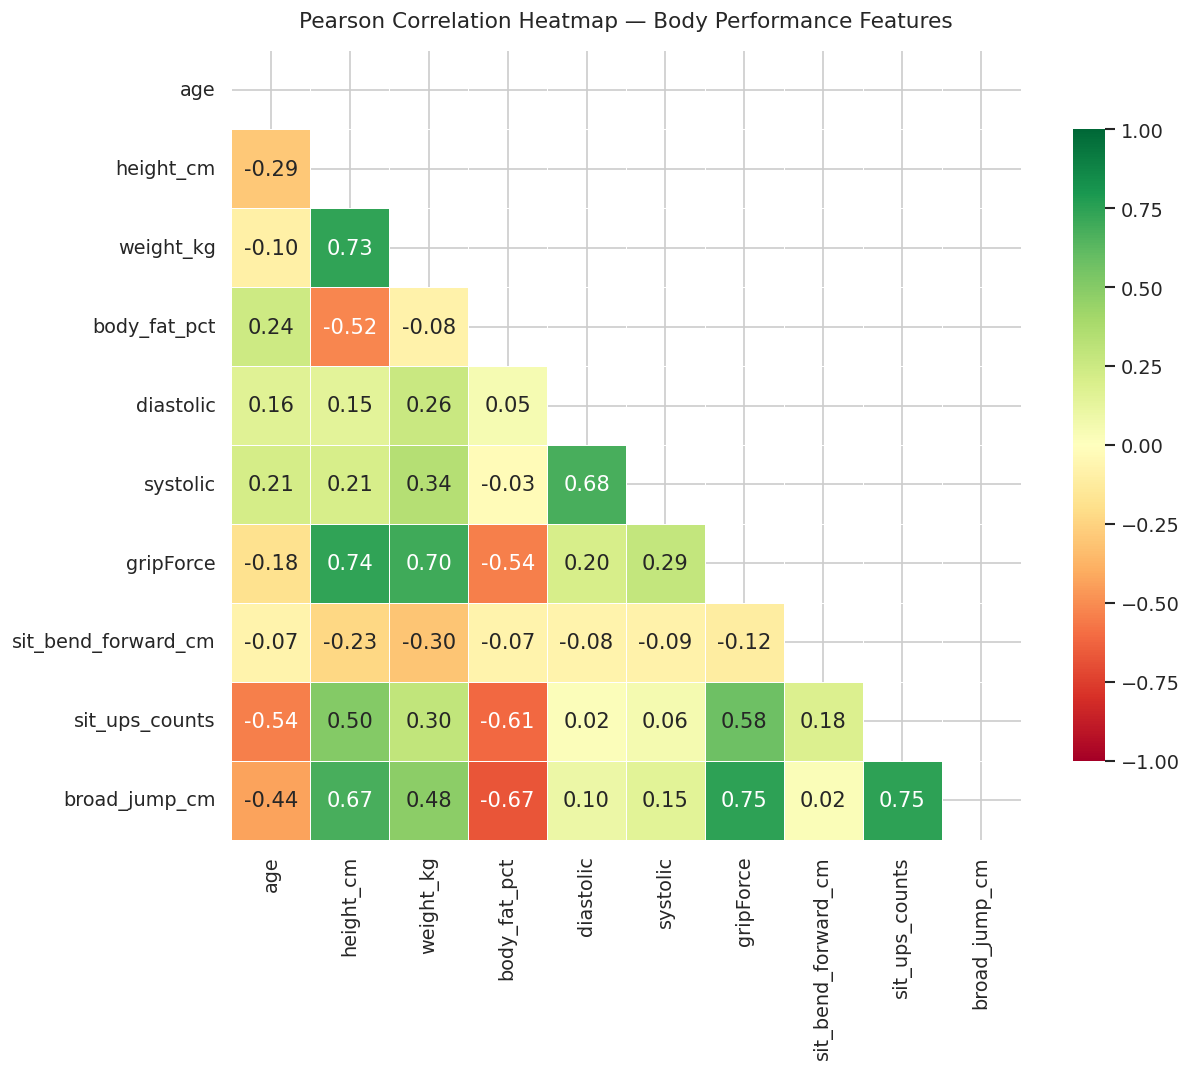

Figure saved as fig_correlation_heatmap.png


In [ ]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 9))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Show lower triangle only

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn',
    center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=ax
)

ax.set_title('Pearson Correlation Heatmap — Body Performance Features', fontsize=13, pad=14)
plt.tight_layout()
plt.savefig('fig_correlation_heatmap.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_correlation_heatmap.png')

In [ ]:
# ── Extract and rank the strongest correlations ───────────────────────────────
corr_pairs = (
    corr_matrix
    .unstack()
    .reset_index()
    .rename(columns={'level_0':'Feature A','level_1':'Feature B', 0:'Correlation'})
)

# Remove self-correlations and duplicates (keep lower triangle)
corr_pairs = corr_pairs[
    corr_pairs['Feature A'] < corr_pairs['Feature B']
].copy()

corr_pairs['Abs Corr'] = corr_pairs['Correlation'].abs()
corr_pairs = corr_pairs.sort_values('Abs Corr', ascending=False)

print('Top 10 Feature Pairs by Absolute Correlation:')
display(corr_pairs.head(10)[['Feature A','Feature B','Correlation']].reset_index(drop=True))

# Get top 5 positive correlations
positive_corr = corr_pairs[corr_pairs['Correlation'] > 0].sort_values('Correlation', ascending=False)
print('\nTop 5 Positive Correlations:')
display(positive_corr.head(5)[['Feature A','Feature B','Correlation']].reset_index(drop=True))

# Get top 5 negative correlations
negative_corr = corr_pairs[corr_pairs['Correlation'] < 0].sort_values('Correlation', ascending=True)
print('\nTop 5 Negative Correlations:')
display(negative_corr.head(5)[['Feature A','Feature B','Correlation']].reset_index(drop=True))

Top 10 Feature Pairs by Absolute Correlation:


,Feature A,Feature B,Correlation
0,broad_jump_cm,sit_ups_counts,0.748334
1,broad_jump_cm,gripForce,0.747272
2,gripForce,height_cm,0.735372
3,height_cm,weight_kg,0.734868
4,gripForce,weight_kg,0.700424
5,diastolic,systolic,0.678175
6,broad_jump_cm,height_cm,0.674586
7,body_fat_pct,broad_jump_cm,-0.674286
8,body_fat_pct,sit_ups_counts,-0.609996
9,gripForce,sit_ups_counts,0.577115



Top 5 Positive Correlations:


,Feature A,Feature B,Correlation
0,broad_jump_cm,sit_ups_counts,0.748334
1,broad_jump_cm,gripForce,0.747272
2,gripForce,height_cm,0.735372
3,height_cm,weight_kg,0.734868
4,gripForce,weight_kg,0.700424



Top 5 Negative Correlations:


,Feature A,Feature B,Correlation
0,body_fat_pct,broad_jump_cm,-0.674286
1,body_fat_pct,sit_ups_counts,-0.609996
2,age,sit_ups_counts,-0.544565
3,body_fat_pct,gripForce,-0.542756
4,body_fat_pct,height_cm,-0.516214


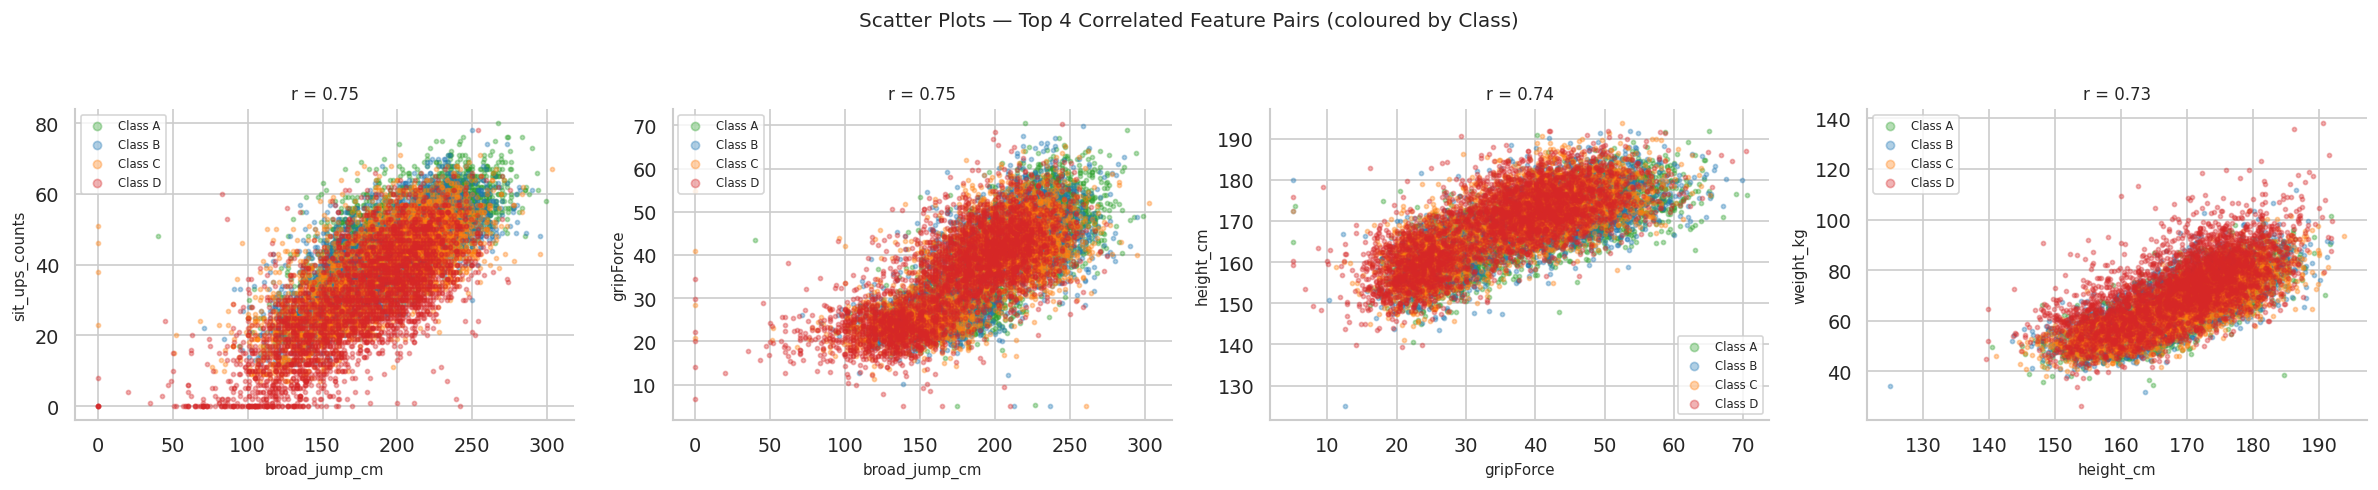

Figure saved as fig_scatter_plots.png


In [ ]:
# ── Scatter plots for the 4 strongest correlated pairs ───────────────────────
top_pairs = corr_pairs.head(4)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

class_palette = {'A':'#2ca02c', 'B':'#1f77b4', 'C':'#ff7f0e', 'D':'#d62728'}

for ax, (_, row) in zip(axes, top_pairs.iterrows()):
    fa, fb = row['Feature A'], row['Feature B']
    for cls in ['A','B','C','D']:
        sub = df[df['class'] == cls]
        ax.scatter(sub[fa], sub[fb], s=6, alpha=0.35,
                   color=class_palette[cls], label=f'Class {cls}')
    ax.set_xlabel(fa, fontsize=9)
    ax.set_ylabel(fb, fontsize=9)
    ax.set_title(f'r = {row["Correlation"]:.2f}', fontsize=10)
    ax.legend(fontsize=7, markerscale=2)

plt.suptitle('Scatter Plots — Top 4 Correlated Feature Pairs (coloured by Class)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('fig_scatter_plots.png', bbox_inches='tight')
plt.show()
print('Figure saved as fig_scatter_plots.png')

In [ ]:
# ── Grouped analysis: mean feature values by gender and class ─────────────────
print('Mean feature values by Gender:')
display(df.groupby('gender', observed=True)[numeric_cols].mean().round(2))

print('\nMean feature values by Performance Class:')
display(df.groupby('class', observed=True)[numeric_cols].mean().round(2))

Mean feature values by Gender:


,age,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm
gender,,,,,,,,,,
F,37.85,160.49,56.91,28.49,75.58,124.01,25.82,18.84,30.88,153.32
M,36.15,173.26,73.58,20.19,80.67,133.88,43.45,13.07,44.94,211.54



Mean feature values by Performance Class:


,age,height_cm,weight_kg,body_fat_pct,diastolic,systolic,gripForce,sit_bend_forward_cm,sit_ups_counts,broad_jump_cm
class,,,,,,,,,,
A,35.27,167.87,64.42,20.53,77.91,129.32,38.62,21.36,47.85,202.75
B,37.07,168.58,66.61,22.04,78.67,130.64,37.91,17.43,42.64,195.33
C,36.70,169.16,66.76,22.64,78.55,129.93,36.58,14.39,38.72,188.63
D,38.06,168.63,72.00,27.74,80.09,131.10,34.75,7.59,29.88,173.82


### 📌 Interpretation
Key findings from the correlation analysis:

1. **Height ↔ Weight (strong positive)**: Taller individuals tend to be heavier — a well-known anthropometric relationship.
2. **Height ↔ Grip Force (moderate positive)**: Taller people tend to have greater muscle mass and thus stronger grip.
3. **Grip Force ↔ Broad Jump (moderate positive)**: Both measure overall muscular strength and power, so they are expected to correlate.
4. **Sit-ups ↔ Broad Jump (moderate positive)**: Both reflect general physical conditioning.
5. **Body Fat % ↔ Sit-ups (negative)**: Higher body fat is associated with fewer sit-ups — excess adipose tissue increases the load in this exercise.
6. **Diastolic ↔ Systolic (positive)**: The two blood pressure readings move together, as expected from the cardiovascular physiology.
7. **Age ↔ Performance features (negative)**: Older participants tend to perform worse on explosive and endurance tasks — a universal decline pattern.

**Implication for modelling**: Performance features (grip force, sit-ups, broad jump) are the most discriminative features for predicting class. Blood pressure and body fat provide complementary physiological context but may add less classification power individually.

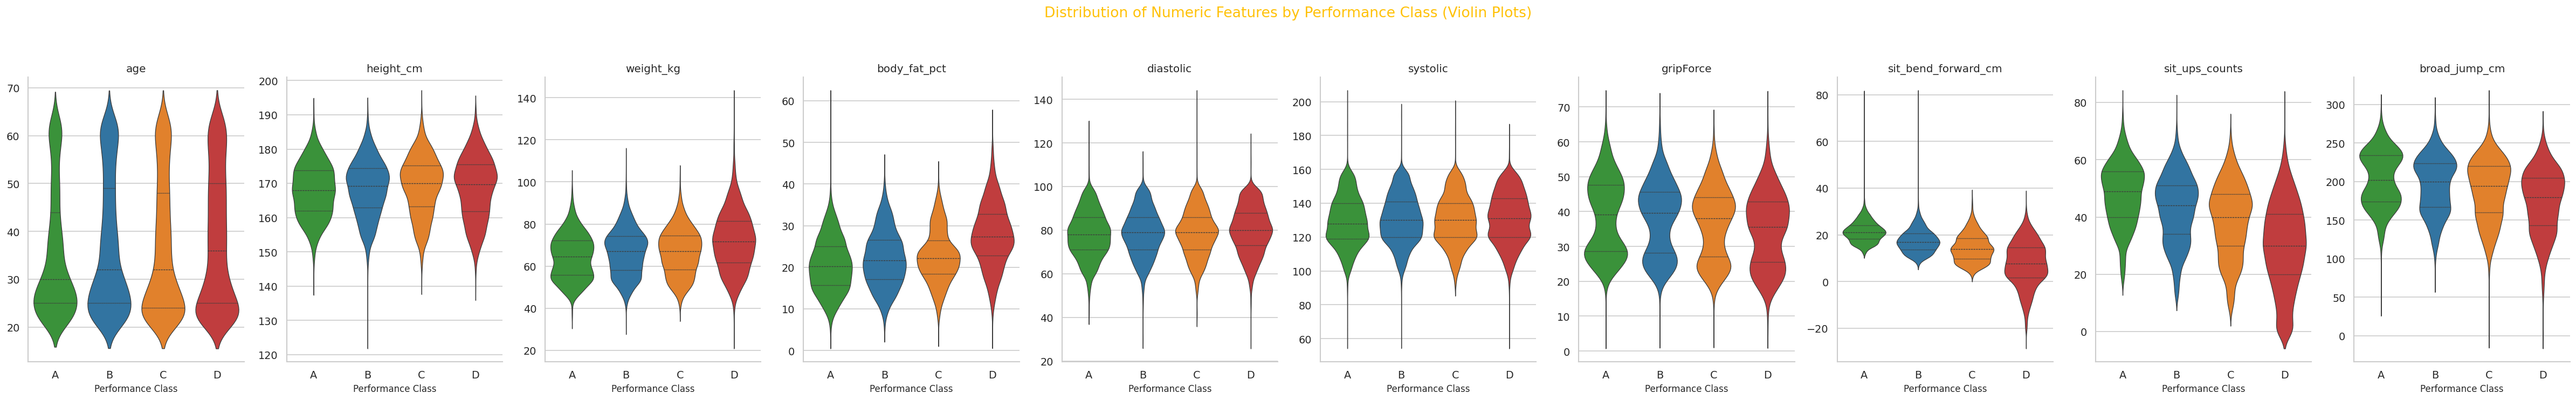

Figure saved as fig_violin_plots_by_class.png


In [ ]:
# ── Violin plots for all numeric features by performance class ────────────────

# Define the order of classes and the color palette for consistency
class_order = ['A', 'B', 'C', 'D']
palette = {'A':'#2ca02c', 'B':'#1f77b4', 'C':'#ff7f0e', 'D':'#d62728'}

numeric_cols = [
    'age', 'height_cm', 'weight_kg', 'body_fat_pct',
    'diastolic', 'systolic', 'gripForce',
    'sit_bend_forward_cm', 'sit_ups_counts', 'broad_jump_cm'
]

# Create a figure with a single row of subplots, making it very wide
# The figure size is dynamically set based on the number of numeric columns
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(len(numeric_cols) * 4, 6))

# Iterate through each numeric column to create a violin plot
for i, col in enumerate(numeric_cols):
    # Use seaborn.violinplot to visualize the distribution of each feature
    # across the different performance classes
    sns.violinplot(data=df, x='class', y=col, ax=axes[i],
                   order=class_order, palette=palette, inner='quartile', linewidth=0.8)
    axes[i].set_title(col, fontsize=12) # Set title for each subplot
    axes[i].set_xlabel('Performance Class', fontsize=10) # Set x-label
    axes[i].set_ylabel('') # Clear y-label to avoid clutter and improve readability

# Add a super title to the entire figure
plt.suptitle('Distribution of Numeric Features by Performance Class (Violin Plots)',
             fontsize=16, y=1.03, color=GOLD)
# Adjust layout to prevent titles and labels from overlapping
plt.tight_layout(rect=[0, 0, 1, 0.98])
# Save the figure to a file
plt.savefig('fig_violin_plots_by_class.png', bbox_inches='tight', dpi=150)
# Display the plot
plt.show()

print('Figure saved as fig_violin_plots_by_class.png')


# 📊 Interpretation of Violin Plots – Numeric Features by Performance Class

The violin plots provide a detailed view of how each numeric feature is distributed across the four performance classes (A → D), allowing us to assess **separation power, variability, and overlap**.

---

## 🔹 1. Physical Strength & Power Features

### gripForce
- Clear decreasing trend from Class A to Class D  
- Class A shows the highest values, while Class D shows the lowest  
- Minimal overlap between classes  

**Insight:**  
This is one of the strongest discriminative features with high predictive power.

---

### broad_jump_cm
- Very strong and clean separation across all classes  
- Each class occupies a distinct range  

**Key Insight:**  
This is the **most important feature** for classification (top predictor).

---

### sit_ups_counts
- Class A clearly outperforms others  
- Noticeable overlap between Classes B and C  

**Insight:**  
Moderately strong feature but less effective than gripForce and broad jump.

---

## 🔹 2. Flexibility Feature

### sit_bend_forward_cm
- Wide distribution within each class  
- Significant overlap across all classes  

**Insight:**  
Weak feature with low discriminative power.

---

## 🔹 3. Body Composition Features

### body_fat_pct
- Clear trend:
  - Lower values in Class A  
  - Higher values in Class D  
- Some overlap exists  

**Insight:**  
Moderately useful feature.

---

### weight_kg
- High overlap between all classes  
- No clear separation pattern  

**Insight:**  
Not a strong standalone predictor.

---

### height_cm
- Nearly identical distributions across all classes  

**Insight:**  
Very weak or non-informative feature.

---

## 🔹 4. Vital Signs

### systolic & diastolic
- Slight variations between classes  
- High overlap  

**Insight:**  
Limited predictive value.

---

## 🔹 5. Age
- Possible slight trend (lower performance associated with higher age)  
- Still shows overlap  

**Insight:**  
Supportive feature but not a key driver.

---

# 🧠 Final Conclusion

The violin plots indicate that performance-related features such as **broad jump and grip strength** are the most discriminative variables, showing clear separation between classes. In contrast, features like **flexibility, height, and vital signs** exhibit high overlap and limited predictive value.

This suggests that **explosive strength and muscular endurance** are the primary factors driving performance classification in this dataset.

---

# 🎯 Feature Importance Summary

## 🔥 Strong Features
- broad_jump_cm 🥇  
- gripForce 🥈  

## 👍 Medium Features
- sit_ups_counts  
- body_fat_pct  

## ❌ Weak Features
- sit_bend_forward_cm  
- height_cm  
- weight_kg  
- systolic  
- diastolic  

---

---
## 5.11 Final EDA Summary

In [ ]:
# ── Final clean dataset stats ─────────────────────────────────────────────────
print('=' * 55)
print('  FINAL CLEAN DATASET SUMMARY')
print('=' * 55)
print(f'  Rows          : {len(df):,}')
print(f'  Columns       : {df.shape[1]}')
print(f'  Missing values: {df.isnull().sum().sum()}')
print(f'  Duplicates    : {df.duplicated().sum()}')
print(f'  Classes       : {sorted(df["class"].unique().tolist())}')
print(f'  Gender split  : {df["gender"].value_counts().to_dict()}')
print('=' * 55)

  FINAL CLEAN DATASET SUMMARY
  Rows          : 13,392
  Columns       : 12
  Missing values: 0
  Duplicates    : 0
  Classes       : ['A', 'B', 'C', 'D']
  Gender split  : {'M': 8467, 'F': 4925}


### ✅ Five Key Insights Discovered in the Data

1. **Performance features separate classes clearly.** Grip force, sit-ups count, and broad jump distance show strong distributional separation across classes A–D. These are the most important predictors for the classification task.

2. **Gender creates a systematic bimodal split.** Height, weight, and grip force all show bimodal distributions because male and female subpopulations have distinct mean values. Gender should be encoded and included as a feature in all models.

3. **Age is inversely related to performance.** Older participants consistently score lower on explosive and endurance tests. Age is therefore an informative, negatively-correlated predictor of class.

4. **Blood pressure provides limited class discrimination.** Diastolic and systolic pressure are only weakly correlated with performance class. They may still contribute marginal signal but are not among the primary predictors.

5. **The class labels are well-balanced.** All four classes (A, B, C, D) contain roughly similar proportions of participants, making the dataset suitable for classification without requiring oversampling or class weighting adjustments.

---

### ⚠️ Five Potential Data Quality Problems

1. **Bimodal distributions without a gender split.** Analysing features like height or weight without stratifying by gender can mask two distinct sub-populations and lead to misleading statistics.

2. **Possible data entry errors in blood pressure.** Some rows may have diastolic ≥ systolic — a physiologically impossible state. These were flagged and corrected during the validity check phase.

3. **Right skew in body fat percentage.** A long right tail suggests some extreme values that could disproportionately influence linear models. These benefit from capping or log transformation.

4. **Outliers in sit-and-bend and grip force.** Both columns contain IQR-flagged outliers that may reflect genuine athletic extremes or measurement errors; careful treatment is required.

5. **Column naming inconsistency.** The raw dataset uses spaces, hyphens, and percent signs in column names, which causes indexing errors in Python. All names were standardised during preprocessing.

---

### 🔧 Recommended Preprocessing Steps for Part 2

1. **Encode `gender`** using binary encoding (M=1, F=0) or one-hot encoding.
2. **Encode `class`** as integers (A=0, B=1, C=2, D=3) for classification models, or use label encoding.
3. **Scale all numeric features** using `StandardScaler` (zero mean, unit variance) before training KNN, SVM, and Neural Network models — all three are sensitive to feature magnitude.
4. **Decision Trees and random forests** do not require scaling, but consistent preprocessing across all pipelines is recommended for fair comparison.
5. **For regression** (predicting `broad_jump_cm`): use the same clean numeric features, drop the `class` column, and apply `StandardScaler` on X.
6. **Feature importance analysis** (from Decision Tree or correlation) can guide optional feature selection before training.

In [ ]:
# ── Save the cleaned dataset for use in Part 2 ────────────────────────────────
df.to_csv('bodyPerformance_cleaned.csv', index=False)
print(f'Cleaned dataset saved to: bodyPerformance_cleaned.csv')
print(f'Final shape: {df.shape}')
print('\nColumn dtypes:')
print(df.dtypes)
print('\nPart 1 — EDA complete. Proceed to Part 2: Model Training.')

Cleaned dataset saved to: bodyPerformance_cleaned.csv
Final shape: (13392, 12)

Column dtypes:
age                     float64
gender                 category
height_cm               float64
weight_kg               float64
body_fat_pct            float64
diastolic               float64
systolic                float64
gripForce               float64
sit_bend_forward_cm     float64
sit_ups_counts            Int64
broad_jump_cm           float64
class                  category
dtype: object

Part 1 — EDA complete. Proceed to Part 2: Model Training.
